# Medical Device Adverse Event Analysis — openFDA API, Python, SQL
**Business question:** Which medical device types generate the most adverse event reports, how is report volume trending, and how clean is the public data?

**Pipeline:** REST API → pandas cleaning → data-quality checks → SQLite → SQL analysis → charts → findings

Data: FDA MAUDE adverse event reports via the public openFDA API (real, public data). Reports are not proof a device caused harm.

In [1]:
import requests, time, sqlite3, json
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_colwidth', 60)

## 1. Pull data from the openFDA REST API

In [3]:
# Free key: https://open.fda.gov/apis/authentication/  (paste yours between the quotes)
API_KEY = "JwFfcHBpwjBb7CcrnWWrjJCMKzGBdzmkMpdJkKpm"

BASE = "https://api.fda.gov/device/event.json"
SEARCH = "date_received:[20250101 TO 20251231]"   # one full year
PAGE, N_PAGES = 1000, 10                           # 10,000 reports

records, log = [], []
for i in range(N_PAGES):
    params = {"search": SEARCH, "limit": PAGE, "skip": i * PAGE}
    if API_KEY:
        params["api_key"] = API_KEY
    for attempt in range(3):                       # retry on errors / rate limits
        r = requests.get(BASE, params=params, timeout=60)
        if r.status_code == 200:
            break
        time.sleep(2 ** attempt)
    r.raise_for_status()
    batch = r.json().get("results", [])
    records.extend(batch)
    log.append((i + 1, len(batch)))
    time.sleep(0.5)                                # be polite to the API
    if len(batch) < PAGE:
        break

print(f"API calls: {len(log)} | raw reports pulled: {len(records):,}")

API calls: 10 | raw reports pulled: 10,000


## 2. Flatten the nested JSON into a table

In [4]:
def first(lst):
    return lst[0] if isinstance(lst, list) and lst else {}

rows = []
for rec in records:
    dev = first(rec.get("device"))
    ofda = dev.get("openfda", {}) or {}
    rows.append({
        "report_id":      rec.get("mdr_report_key"),
        "date_received":  rec.get("date_received"),
        "date_of_event":  rec.get("date_of_event"),
        "event_type":     rec.get("event_type"),
        "report_source":  rec.get("report_source_code"),
        "generic_name":   dev.get("generic_name"),
        "brand_name":     dev.get("brand_name"),
        "manufacturer":   dev.get("manufacturer_d_name"),
        "product_code":   dev.get("device_report_product_code"),
        "device_class":   ofda.get("device_class"),
        "specialty":      ofda.get("medical_specialty_description"),
    })
raw = pd.DataFrame(rows)
print(raw.shape); raw.head()

(10000, 11)


,report_id,date_received,date_of_event,event_type,report_source,generic_name,brand_name,manufacturer,product_code,device_class,specialty
0,21050632,20250101,20241209,Malfunction,Manufacturer report,"SYSTEM, BALLOON, INTRA-AORTIC AND CONTROL","CARDIOSAVE HYBRID, TYPE G PLUG",DATASCOPE CORP.,DSP,2,Cardiovascular
1,21050633,20250101,20241211,Malfunction,Manufacturer report,"SYSTEM, BALLOON, INTRA-AORTIC AND CONTROL","CARDIOSAVE HYBRID, TYPE B PLUG",DATASCOPE CORP.,DSP,2,Cardiovascular
2,21050634,20250101,20241201,Injury,Manufacturer report,"AUTOMATED INSULIN DOSING DEVICE SYSTEM, SINGLE HORMONAL ...",MINIMED 780G US SYSTEM BLE CONNECT 3.0 MG/DL,MEDTRONIC PUERTO RICO OPERATIONS CO.,OZP,3,Unknown
3,21050635,20250101,20231009,Injury,Manufacturer report,"VENTILATOR, NON-CONTINUOUS (RESPIRATOR)",DREAMSTATION AUTO CPAP,"RESPIRONICS, INC.",BZD,2,Anesthesiology
4,21050636,20250101,20231009,Injury,Manufacturer report,"VENTILATOR, NON-CONTINUOUS (RESPIRATOR)",DREAMSTATION AUTO CPAP,"RESPIRONICS, INC.",BZD,2,Anesthesiology


## 3. Data-quality audit (before cleaning)

In [5]:
def audit(df, label):
    out = pd.DataFrame({
        "missing_%": (df.isna().mean() * 100).round(1),
        "unique":    df.nunique(),
    })
    print(f"--- {label}: {len(df):,} rows | duplicate report IDs: {df['report_id'].duplicated().sum():,}")
    return out
audit(raw, "RAW")

--- RAW: 10,000 rows | duplicate report IDs: 0


,missing_%,unique
report_id,0.0,10000
date_received,0.0,2
date_of_event,4.6,570
event_type,0.0,4
report_source,0.0,4
generic_name,0.0,709
brand_name,0.0,2093
manufacturer,0.0,367
product_code,0.0,381
device_class,0.0,6


## 4. Clean and standardize

In [6]:
df = raw.copy()
n0 = len(df)

# remove duplicate reports
df = df.drop_duplicates(subset="report_id")
n_dupes = n0 - len(df)

# parse dates (YYYYMMDD strings) — bad values become NaT
for c in ["date_received", "date_of_event"]:
    df[c] = pd.to_datetime(df[c], format="%Y%m%d", errors="coerce")

# standardize text fields
for c in ["generic_name", "brand_name", "manufacturer", "event_type", "specialty"]:
    df[c] = df[c].astype("string").str.strip().str.upper()

# normalize event types
df["event_type"] = df["event_type"].replace({"NO ANSWER PROVIDED": pd.NA, "*": pd.NA}).fillna("UNKNOWN")

# reporting lag (days between event and FDA receipt); flag impossible values
df["lag_days"] = (df["date_received"] - df["date_of_event"]).dt.days
bad_lag = ((df["lag_days"] < 0) | (df["lag_days"] > 3650)).sum()
df.loc[(df["lag_days"] < 0) | (df["lag_days"] > 3650), "lag_days"] = pd.NA

print(f"Removed duplicates: {n_dupes:,} | invalid lags flagged: {bad_lag:,} | clean rows: {len(df):,}")
audit(df, "CLEAN")

Removed duplicates: 0 | invalid lags flagged: 23 | clean rows: 10,000
--- CLEAN: 10,000 rows | duplicate report IDs: 0


,missing_%,unique
report_id,0.0,10000
date_received,0.0,2
date_of_event,4.6,570
event_type,0.0,4
report_source,0.0,4
generic_name,0.0,696
brand_name,0.0,2089
manufacturer,0.0,365
product_code,0.0,381
device_class,0.0,6


## 5. Load into SQLite

In [7]:
con = sqlite3.connect("device_events.db")
out = df.copy()
for c in ["date_received", "date_of_event"]:
    out[c] = out[c].dt.strftime("%Y-%m-%d")
out.to_sql("events", con, if_exists="replace", index=False)
sql = lambda q: pd.read_sql(q, con)
sql("SELECT COUNT(*) AS rows_loaded FROM events")

,rows_loaded
0,10000


## 6. SQL analysis

In [8]:
# Q1: event type breakdown
q1 = sql("""
SELECT event_type, COUNT(*) AS reports,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM events), 1) AS pct
FROM events GROUP BY event_type ORDER BY reports DESC""")
q1

,event_type,reports,pct
0,MALFUNCTION,6150,61.5
1,INJURY,3790,37.9
2,DEATH,59,0.6
3,OTHER,1,0.0


In [9]:
# Q2: top 10 device types by report volume, with injury/death share
q2 = sql("""
SELECT generic_name, COUNT(*) AS reports,
       SUM(event_type IN ('INJURY','DEATH')) AS serious,
       ROUND(100.0 * SUM(event_type IN ('INJURY','DEATH')) / COUNT(*), 1) AS serious_pct
FROM events WHERE generic_name IS NOT NULL
GROUP BY generic_name ORDER BY reports DESC LIMIT 10""")
q2

,generic_name,reports,serious,serious_pct
0,ENDOSSEOUS DENTAL IMPLANT,1873,1873,100.0
1,ALTERNATE CONTROLLER ENABLED INSULIN INFUSION PUMP,1482,160,10.8
2,"AUTOMATED INSULIN DOSING DEVICE SYSTEM, SINGLE HORMONAL ...",697,67,9.6
3,CONTINUOUS GLUCOSE MONITOR,609,8,1.3
4,ALTERNATE CONTROLLER ENABLED INFUSION PUMP,464,31,6.7
5,"IMPLANT, ENDOSSEOUS, ROOT-FORM",378,378,100.0
6,"PUMP, INFUSION",171,5,2.9
7,AUTOMATED DISPENSING CABINET,117,0,0.0
8,"VENTILATOR, NON-CONTINUOUS (RESPIRATOR)",111,28,25.2
9,"PUMP, INFUSION, INSULIN, TO BE USED WITH INVASIVE GLUCOS...",103,0,0.0


In [10]:
# Q3: monthly volume with month-over-month % change (window function)
q3 = sql("""
WITH m AS (
  SELECT substr(date_received, 1, 7) AS month, COUNT(*) AS reports
  FROM events WHERE date_received IS NOT NULL GROUP BY month)
SELECT month, reports,
       ROUND(100.0 * (reports - LAG(reports) OVER (ORDER BY month))
             / LAG(reports) OVER (ORDER BY month), 1) AS mom_pct
FROM m ORDER BY month""")
q3

,month,reports,mom_pct
0,2025-01,10000,None


In [11]:
# Q4: top manufacturers + median-ish reporting lag
q4 = sql("""
SELECT manufacturer, COUNT(*) AS reports, ROUND(AVG(lag_days), 0) AS avg_lag_days
FROM events WHERE manufacturer IS NOT NULL
GROUP BY manufacturer ORDER BY reports DESC LIMIT 10""")
q4

,manufacturer,reports,avg_lag_days
0,TANDEM DIABETES CARE,1892,18.0
1,INSTITUT STRAUMANN AG,1119,74.0
2,MEDTRONIC PUERTO RICO OPERATIONS CO.,835,35.0
3,"DEXCOM, INC.",620,40.0
4,NOBEL BIOCARE AB GÖTEBORG,364,308.0
5,JJGC S.A.,356,89.0
6,UNOMEDICAL UM-D,311,85.0
7,INSULET CORPORATION,311,32.0
8,MEDTRONIC MINIMED,246,23.0
9,BOSTON SCIENTIFIC CORPORATION,198,85.0


In [12]:
# Q5: reports by medical specialty (where openFDA classified it)
q5 = sql("""
SELECT COALESCE(specialty, 'UNCLASSIFIED') AS specialty, COUNT(*) AS reports
FROM events GROUP BY 1 ORDER BY reports DESC LIMIT 10""")
q5

,specialty,reports
0,CLINICAL CHEMISTRY,2990
1,DENTAL,2438
2,UNKNOWN,1734
3,GENERAL HOSPITAL,809
4,CARDIOVASCULAR,418
5,"GENERAL, PLASTIC SURGERY",379
6,ANESTHESIOLOGY,362
7,"GASTROENTEROLOGY, UROLOGY",358
8,ORTHOPEDIC,274
9,OPHTHALMIC,62


## 7. Charts

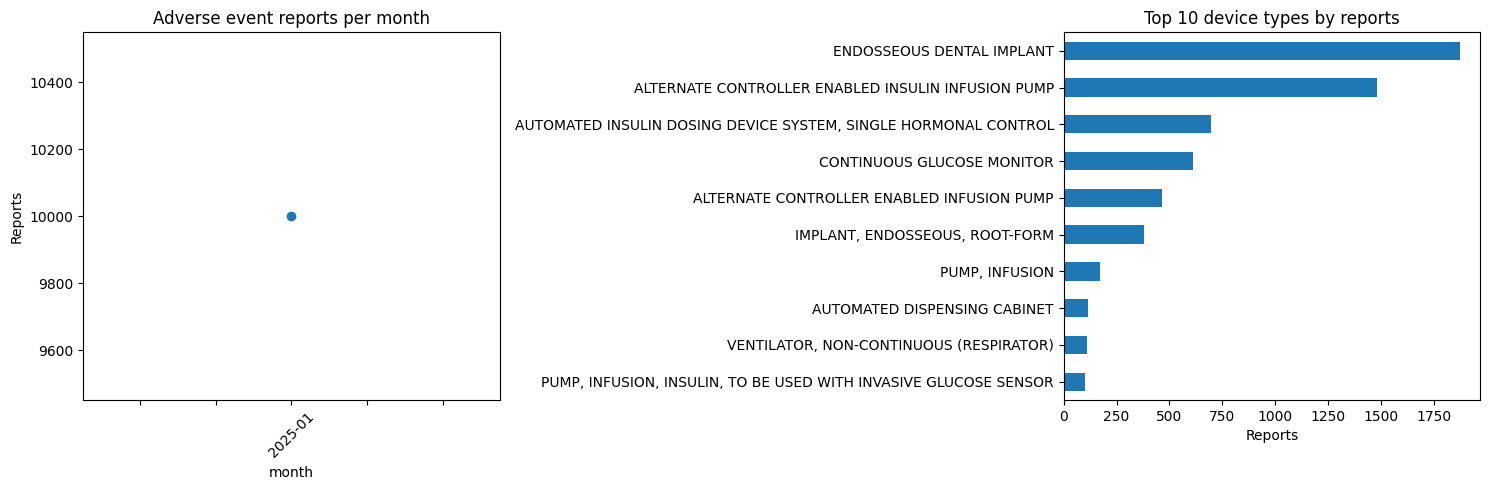

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
q3.plot(x="month", y="reports", marker="o", ax=ax[0], legend=False)
ax[0].set_title("Adverse event reports per month"); ax[0].set_ylabel("Reports"); ax[0].tick_params(axis="x", rotation=45)
q2.sort_values("reports").plot.barh(x="generic_name", y="reports", ax=ax[1], legend=False)
ax[1].set_title("Top 10 device types by reports"); ax[1].set_xlabel("Reports"); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig("dashboard.png", dpi=150); plt.show()

## 8. Validation checks (automated)

In [14]:
checks = {
    "no duplicate report IDs":        df["report_id"].duplicated().sum() == 0,
    "all rows loaded to SQL":         sql("SELECT COUNT(*) n FROM events")["n"][0] == len(df),
    "event-type % sums to ~100":      abs(q1["pct"].sum() - 100) < 0.5,
    "no negative reporting lags":     (df["lag_days"].dropna() >= 0).all(),
    "all received dates in 2025":     df["date_received"].dropna().dt.year.eq(2025).all(),
}
for k, v in checks.items(): print(("PASS " if v else "FAIL ") + k)
assert all(checks.values()), "A validation check failed"

PASS no duplicate report IDs
PASS all rows loaded to SQL
PASS event-type % sums to ~100
PASS no negative reporting lags
PASS all received dates in 2025


## 9. Results summary — copy these numbers to your resume

In [15]:
top = q2.iloc[0]
print(f"Reports pulled: {len(records):,} via {len(log)} API calls")
print(f"Duplicates removed: {n_dupes:,} | invalid lags flagged: {bad_lag:,}")
print(f"Clean rows in SQL: {len(df):,}")
print(f"Top device type: {top['generic_name']} ({top['reports']:,} reports, {top['serious_pct']}% injury/death)")
print(f"Malfunction share: {q1.set_index('event_type')['pct'].get('MALFUNCTION', 0)}%")
print(f"Validation checks passed: {sum(checks.values())}/{len(checks)}")

Reports pulled: 10,000 via 10 API calls
Duplicates removed: 0 | invalid lags flagged: 23
Clean rows in SQL: 10,000
Top device type: ENDOSSEOUS DENTAL IMPLANT (1,873 reports, 100.0% injury/death)
Malfunction share: 61.5%
Validation checks passed: 5/5


## 10. Findings (PAFR) — fill in after running
- **Problem:**
- **Approach:** Pulled N reports from the openFDA REST API, cleaned/deduplicated in pandas, loaded to SQLite, analyzed with SQL (aggregations, CTE, LAG window function), and ran 5 automated validation checks.
- **Findings:**
- **Recommendation:**